In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error


In [2]:
df = pd.read_csv("uber.csv")
df

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...,...,...
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [3]:
df.shape

(200000, 9)

In [4]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB


In [6]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [7]:
df = df.drop(columns=['Unnamed: 0' , 'key'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        200000 non-null  float64
 1   pickup_datetime    200000 non-null  str    
 2   pickup_longitude   200000 non-null  float64
 3   pickup_latitude    200000 non-null  float64
 4   dropoff_longitude  199999 non-null  float64
 5   dropoff_latitude   199999 non-null  float64
 6   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 10.7 MB


In [8]:
df = df.dropna()
df

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...
199995,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [9]:
df = df.drop_duplicates()
df

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...
199995,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [10]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df.info()

<class 'pandas.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   fare_amount        199999 non-null  float64            
 1   pickup_datetime    199999 non-null  datetime64[us, UTC]
 2   pickup_longitude   199999 non-null  float64            
 3   pickup_latitude    199999 non-null  float64            
 4   dropoff_longitude  199999 non-null  float64            
 5   dropoff_latitude   199999 non-null  float64            
 6   passenger_count    199999 non-null  int64              
dtypes: datetime64[us, UTC](1), float64(5), int64(1)
memory usage: 12.2 MB


In [11]:
df['Year'] = df['pickup_datetime'].dt.year
df['Month'] = df['pickup_datetime'].dt.month
df['Day'] = df['pickup_datetime'].dt.day
df['DayOfWeek'] = df['pickup_datetime'].dt.dayofweek
df['Hour'] = df['pickup_datetime'].dt.hour

df.info()
df

<class 'pandas.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   fare_amount        199999 non-null  float64            
 1   pickup_datetime    199999 non-null  datetime64[us, UTC]
 2   pickup_longitude   199999 non-null  float64            
 3   pickup_latitude    199999 non-null  float64            
 4   dropoff_longitude  199999 non-null  float64            
 5   dropoff_latitude   199999 non-null  float64            
 6   passenger_count    199999 non-null  int64              
 7   Year               199999 non-null  int32              
 8   Month              199999 non-null  int32              
 9   Day                199999 non-null  int32              
 10  DayOfWeek          199999 non-null  int32              
 11  Hour               199999 non-null  int32              
dtypes: datetime64[us, UTC](1), float64(5), int32(5

C:\Users\Hemant\AppData\Local\Temp\ipykernel_11492\690262621.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['DayOfWeek'] = df['pickup_datetime'].dt.dayofweek


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Year,Month,Day,DayOfWeek,Hour
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,7,3,19
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,17,4,20
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,24,0,21
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,26,4,8
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,28,3,17
...,...,...,...,...,...,...,...,...,...,...,...,...
199995,3.0,2012-10-28 10:49:00+00:00,-73.987042,40.739367,-73.986525,40.740297,1,2012,10,28,6,10
199996,7.5,2014-03-14 01:09:00+00:00,-73.984722,40.736837,-74.006672,40.739620,1,2014,3,14,4,1
199997,30.9,2009-06-29 00:42:00+00:00,-73.986017,40.756487,-73.858957,40.692588,2,2009,6,29,0,0
199998,14.5,2015-05-20 14:56:25+00:00,-73.997124,40.725452,-73.983215,40.695415,1,2015,5,20,2,14


In [12]:
def haversine(lat1,lon1,lat2,lon2):
    lat1,lon1,lat2,lon2 = map(np.radians , [lat1,lon1,lat2,lon2])
    dlat = lat1 - lat2
    dlon = lon1 - lon2
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2

    return 2* 6371* np.arcsin(np.sqrt(a))

In [13]:
df['Distance'] = haversine(df['pickup_longitude'] , df['pickup_latitude'] ,df['dropoff_longitude'],df['dropoff_latitude'])
df

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Year,Month,Day,DayOfWeek,Hour,Distance
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,7,3,19,0.465181
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,17,4,20,0.678728
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,24,0,21,4.823521
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,26,4,8,1.261639
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,28,3,17,5.369902
...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,3.0,2012-10-28 10:49:00+00:00,-73.987042,40.739367,-73.986525,40.740297,1,2012,10,28,6,10,0.064177
199996,7.5,2014-03-14 01:09:00+00:00,-73.984722,40.736837,-74.006672,40.739620,1,2014,3,14,4,1,2.442219
199997,30.9,2009-06-29 00:42:00+00:00,-73.986017,40.756487,-73.858957,40.692588,2,2009,6,29,0,0,14.264792
199998,14.5,2015-05-20 14:56:25+00:00,-73.997124,40.725452,-73.983215,40.695415,1,2015,5,20,2,14,1.800095


In [14]:
df =df[ df['fare_amount'] > 0]
df =df[ df['Distance'] > 0]
df =df[ df['passenger_count'] > 0]

df

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,Year,Month,Day,DayOfWeek,Hour,Distance
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,2015,5,7,3,19,0.465181
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,2009,7,17,4,20,0.678728
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,2009,8,24,0,21,4.823521
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,2009,6,26,4,8,1.261639
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,2014,8,28,3,17,5.369902
...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,3.0,2012-10-28 10:49:00+00:00,-73.987042,40.739367,-73.986525,40.740297,1,2012,10,28,6,10,0.064177
199996,7.5,2014-03-14 01:09:00+00:00,-73.984722,40.736837,-74.006672,40.739620,1,2014,3,14,4,1,2.442219
199997,30.9,2009-06-29 00:42:00+00:00,-73.986017,40.756487,-73.858957,40.692588,2,2009,6,29,0,0,14.264792
199998,14.5,2015-05-20 14:56:25+00:00,-73.997124,40.725452,-73.983215,40.695415,1,2015,5,20,2,14,1.800095


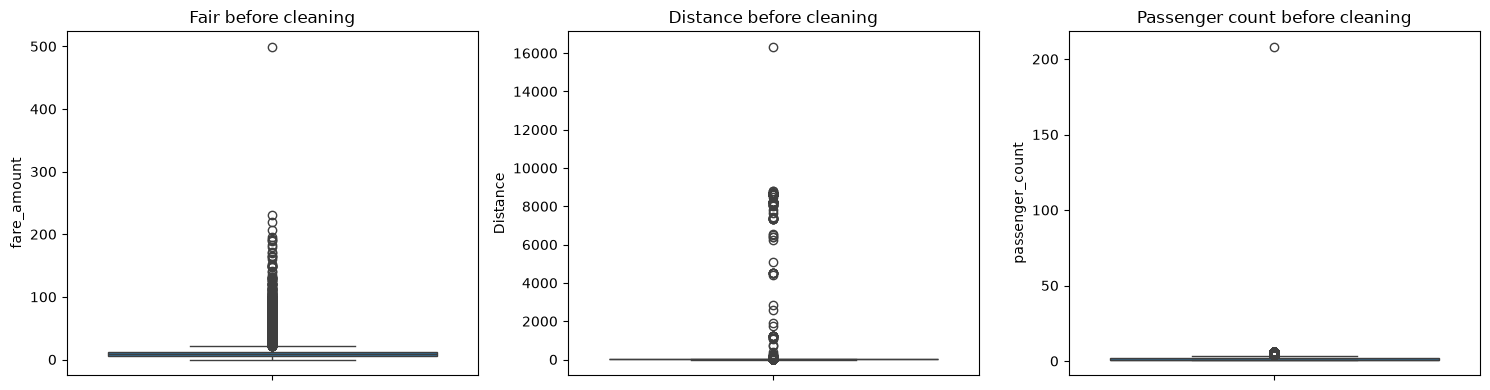

In [15]:
fig , axes = plt.subplots(1,3,figsize=(15,4))

sns.boxplot(y=df['fare_amount'] , ax = axes[0])
axes[0].set_title('Fair before cleaning')
sns.boxplot(y=df['Distance'] , ax = axes[1])
axes[1].set_title('Distance before cleaning')
sns.boxplot(y=df['passenger_count'] , ax = axes[2])
axes[2].set_title('Passenger count before cleaning')


plt.tight_layout()
plt.show()



In [16]:
def check_outliers(col):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    q = q3 - q1

    low , high = q1 - 1.5*q , q3+1.5*q

    n = ((df[col] < low ) | (df[col] > high)).sum()
    print(f"{col} : allowed range {low} to {high} ---> {n} outliers")

    

In [17]:
for c in ['fare_amount','Distance','passenger_count']:
    check_outliers(c)
    

fare_amount : allowed range -3.75 to 22.25 ---> 16620 outliers
Distance : allowed range -2.104851979541462 to 5.850554389747048 ---> 17082 outliers
passenger_count : allowed range -0.5 to 3.5 ---> 21913 outliers


In [18]:
def fix_outliers(col):
    global df
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    q = q3 - q1

    low , high = q1 - 1.5*q , q3+1.5*q

    df = df[ (df[col] >= low) & (df[col] <= high) ]


In [19]:
len(df)

193657

In [20]:
for i in ['fare_amount','Distance']:
   fix_outliers(i)

df = df[ (df['passenger_count'] >= 0) & (df['passenger_count'] <= 6) ]

In [21]:
for c in ['fare_amount','Distance','passenger_count']:
    check_outliers(c)

fare_amount : allowed range -1.4999999999999991 to 17.7 ---> 5173 outliers
Distance : allowed range -1.3836352290331058 to 4.451110193594301 ---> 2741 outliers
passenger_count : allowed range -0.5 to 3.5 ---> 19061 outliers


In [22]:
len(df)

168877

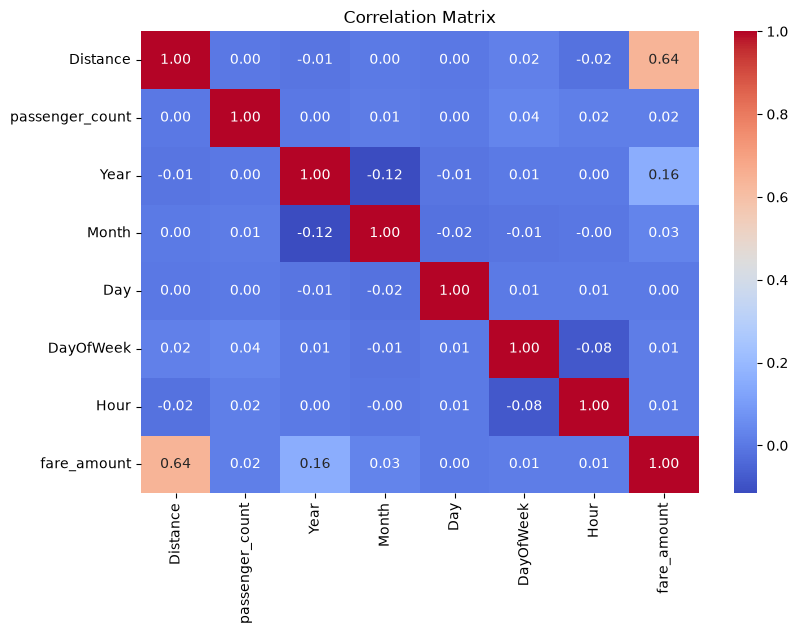

In [23]:
features = ['Distance', 'passenger_count', 'Year', 'Month', 'Day', 'DayOfWeek', 'Hour']

corr = df[features + ['fare_amount']].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')

plt.title('Correlation Matrix')
plt.show()


In [24]:
print(corr['fare_amount'].sort_values(ascending=False))

fare_amount        1.000000
Distance           0.639351
Year               0.156311
Month              0.030049
passenger_count    0.016347
DayOfWeek          0.012255
Hour               0.011199
Day                0.004227
Name: fare_amount, dtype: float64


In [25]:
#train and test

x = df[features]
y = df['fare_amount']
x_train , x_test , y_train ,y_test = train_test_split(x,y,test_size=0.2,random_state=42)


In [26]:
#Linear Regression:
lr = LinearRegression()
lr.fit(x_train,y_train)
lr_pred = lr.predict(x_test)

In [27]:
#Random Forest
rf = RandomForestRegressor(max_depth=15,n_estimators=100,n_jobs=-1,random_state=42)
rf.fit(x_train,y_train)
rf_pred = rf.predict(x_test)


In [28]:
def eval(name,model,pred):
    r2_train = model.score(x_train,y_train)
    r2_test = r2_score(y_test,pred)
    mae = mean_absolute_error(y_test,pred)
    mse = mean_squared_error(y_test,pred)
    rmse = np.sqrt(mse)

    return {'Model':name,'r2_train':r2_train,'r2_test':r2_test,'mae':mae,'mse':mse,'rmse':rmse }

In [29]:
results = pd.DataFrame([eval('Linear Regression',lr,lr_pred),eval('Random Forest',rf,rf_pred)])
print(results.round(3).to_string(index=False))

            Model  r2_train  r2_test   mae   mse  rmse
Linear Regression     0.439    0.436 2.179 8.193 2.862
    Random Forest     0.673    0.447 2.153 8.027 2.833


In [30]:
comparison = pd.DataFrame({'actual': y_test[:10].round(2) , 'LR': lr_pred[:10].round(2), 'RF': rf_pred[:10].round(2)})
comparison

,actual,LR,RF
67458,6.9,9.11,8.18
189010,5.0,8.69,8.63
180813,10.0,10.92,11.85
34706,10.1,9.35,9.23
117645,7.7,9.68,9.74
10144,5.7,6.72,7.15
187990,5.7,8.37,8.08
80122,16.9,13.42,14.07
64770,11.3,10.14,9.99
53712,12.5,13.95,15.60


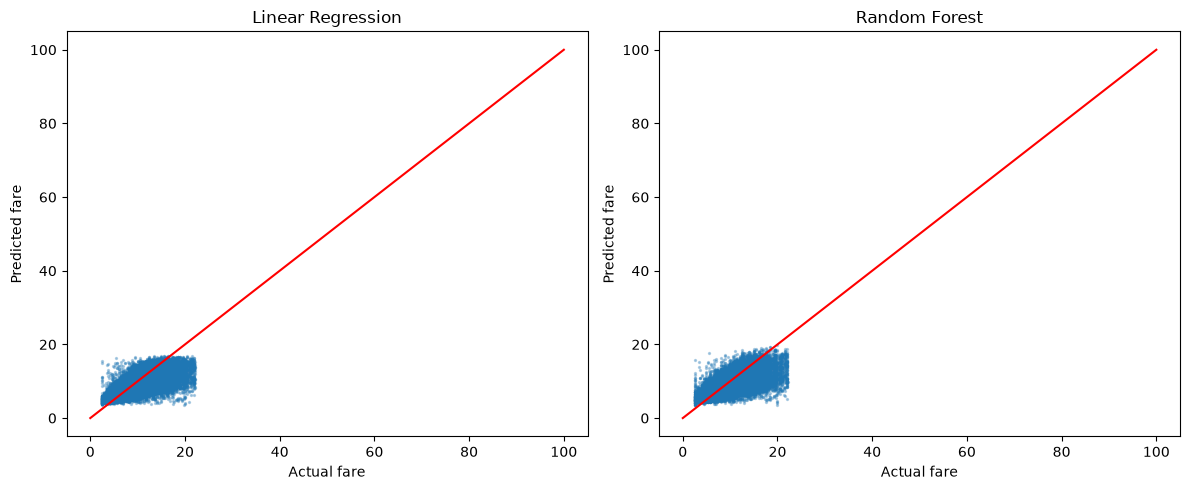

In [31]:
fig , axes = plt.subplots(1,2,figsize=(12,5))
for ax,pred,title in zip(axes,[lr_pred,rf_pred],["Linear Regression" , "Random Forest"]):
    ax.scatter(y_test,pred,s=2,alpha=0.3)
    ax.plot([0,100],[0,100],color='red')
    ax.set_xlabel('Actual fare')
    ax.set_ylabel('Predicted fare')
    ax.set_title(title)

plt.tight_layout()
plt.show()

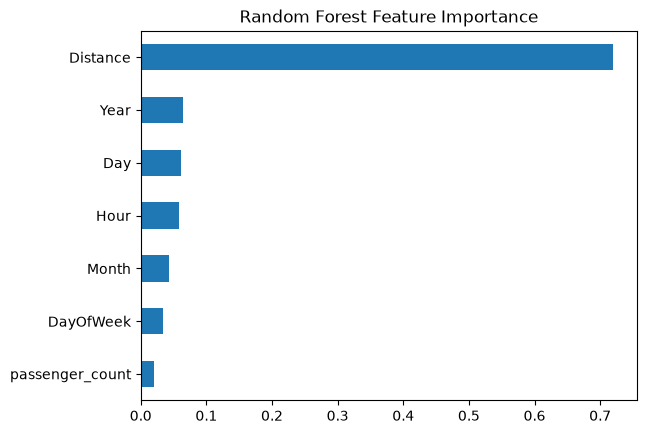

In [32]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind='barh', title='Random Forest Feature Importance')
plt.show()